# 03 — Model Comparison

This notebook runs the four-model comparison (Ridge / Random Forest / Gradient Boosting / SVR) separately for UTS, YS, and elongation, using `GroupKFold` by DOI, and reports train-vs-held-out metrics plus OOF diagnostics.

All the modelling/CV mechanics come from `modelling_lib.run_target_experiment` / `modelling_lib.aggregate_fold_metrics` / `modelling_lib.doi_level_mae_summary` — this notebook only configures inputs and inspects outputs.

Fixed before any model is run, and never revisited afterward: the feature lists and cohort (from 02), the fold-support check below, model default hyperparameters (`modelling_lib.MODEL_FACTORIES` — Ridge alpha=1.0, RandomForest/GradientBoosting n_estimators=100, SVR defaults, all with `random_state=42`), and the same `GroupKFold` split reused across all 4 models. No feature, cohort, or outlier decision changes based on a result seen in this notebook.


## Imports

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "modelling" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from literature_pipeline.modelling import dataset_contract as dc
from literature_pipeline.modelling import modelling_lib as ml

# NOTE: this notebook is a thin experiment/analysis layer over modelling_lib.py.
# No modelling/CV logic is duplicated here.

## Load dataset and feature configuration (independently of 01/02 — same shared functions)


In [2]:
FINAL_DATASET_PATH = PROJECT_ROOT / "data" / "datasets_v2" / "production_run" / "cpp_dataset_v2.csv"
MODEL_NAMES = list(ml.MODEL_FACTORIES)  # ["ridge", "random_forest", "gradient_boosting", "svr"]
BASELINE_NAME = "dummy_mean"  # DummyRegressor(strategy="mean") -- reference line, not a 5th research model
RANDOM_STATE = ml.DEFAULT_RANDOM_STATE

# Fixed at 5-fold for ALL THREE targets, as agreed -- an earlier run used 8-fold for
# UTS/YS by mistake (procedural error, corrected here). One explicit constant, no
# per-target tuning.
MODEL_CV_N_SPLITS = 5

df_raw = pd.read_csv(FINAL_DATASET_PATH)
df = ml.apply_known_data_corrections(df_raw)
target_configs = ml.build_target_configs(df)
for target, cfg in target_configs.items():
    print(f"{target}: {len(cfg['feature_sets']['composition'])} features, primary_n={cfg['primary_n']}, "
          f"model_target_column={cfg['model_target_column']!r}")

UTS_MPa: 10 features, primary_n=155, model_target_column='UTS_MPa_corrected'
YS_MPa: 10 features, primary_n=153, model_target_column='YS_MPa'
elongation_pct: 7 features, primary_n=92, model_target_column='elongation_pct'


## Verify (not assume): the UTS model uses `UTS_MPa_corrected`, including the audited 1.2 GPa row as 1200 MPa

Printed directly, not inferred from code reading alone.


In [3]:
problem_row = df[(df["doi"] == "10.1016/j.jmrt.2021.07.045") & (df["observation_id"] == "M1-P1-O1")].iloc[0]
print("raw UTS_MPa (never mutated):", problem_row["UTS_MPa"])
print("UTS_MPa_corrected (what the model actually sees):", problem_row["UTS_MPa_corrected"])
print("target_configs['UTS_MPa']['model_target_column']:", target_configs["UTS_MPa"]["model_target_column"])

# Trace the exact value the cohort construction below will feed into run_target_experiment
# for this specific row, using the SAME logic the cohort cell uses (not a separate check).
_value_col = target_configs["UTS_MPa"]["model_target_column"]
_y_value_used_by_model = problem_row[_value_col]
print("y_value_used_by_model:", _y_value_used_by_model)
assert _y_value_used_by_model == 1200.0, f"expected 1200.0, got {_y_value_used_by_model} -- UTS correction not in effect"

raw UTS_MPa (never mutated): 1.2
UTS_MPa_corrected (what the model actually sees): 1200.0
target_configs['UTS_MPa']['model_target_column']: UTS_MPa_corrected
y_value_used_by_model: 1200.0


## Build each target's modelling cohort (primary and composition-present, per 02's decision)


In [4]:
cohorts = {}
for target, cfg in target_configs.items():
    value_col = cfg["model_target_column"]
    primary_mask = ml.target_cohort_masks(df, target)["primary"]
    has_composition = df[dc.CORE_COMPOSITION_ELEMENTS].notna().any(axis=1)
    cohort_mask = primary_mask & has_composition
    sub = df[cohort_mask].copy()
    sub[target] = sub[value_col]  # run_target_experiment reads df[target] -- point it at the corrected column
    cohorts[target] = sub
    print(f"{target}: cohort n={len(sub)}, unique DOI={sub['doi'].nunique()}, "
          f"using column {value_col!r}")

UTS_MPa: cohort n=94, unique DOI=19, using column 'UTS_MPa_corrected'
YS_MPa: cohort n=95, unique DOI=20, using column 'YS_MPa'
elongation_pct: cohort n=52, unique DOI=12, using column 'elongation_pct'


## Fold-support check, before any model is run

For each target's features, across every training split its `GroupKFold` would actually produce: the minimum non-null observation/DOI count seen in any training fold, and whether a feature goes completely empty in some fold. `build_preprocessor` uses `keep_empty_features=True`, so this wouldn't crash even if it happened — but a feature that would go empty in a fold gets flagged here explicitly rather than only silently tolerated.


In [5]:
fold_support_by_target = {}
for target, cfg in target_configs.items():
    sub = cohorts[target]
    cv = ml.make_group_kfold(sub, min_splits=MODEL_CV_N_SPLITS, max_splits=MODEL_CV_N_SPLITS)
    support = ml.fold_support_table(sub, cfg["feature_sets"]["composition"], cv, sub["doi"])
    fold_support_by_target[target] = support
    print(f"=== {target} (n_splits={cv.n_splits}) ===")
    print(support.to_string(index=False))
    n_empty = int(support["empty_in_any_training_fold"].sum())
    if n_empty:
        print(f"  *** {n_empty} feature(s) go completely empty in at least one training fold -- flagged, not silently tolerated ***")
    print()

=== UTS_MPa (n_splits=5) ===
feature  min_train_n_observations  min_train_n_DOI  empty_in_any_training_fold
     Si                        75               15                       False
      C                        68               14                       False
     Mn                        65               14                       False
     Cr                        48               10                       False
      P                        41                9                       False
      S                        41                9                       False
     Al                        34                9                       False
     Ni                        27                5                       False
      N                        17                3                       False
     Mo                        11                3                       False

=== YS_MPa (n_splits=5) ===
feature  min_train_n_observations  min_train_n_DOI  empty_in_any_training

## Run all 4 models, same splits, for each target


In [6]:
experiment_results = {}
for target, cfg in target_configs.items():
    sub = cohorts[target]
    experiment_results[target] = ml.run_target_experiment(
        sub, target, cfg["feature_sets"]["composition"], model_names=MODEL_NAMES + [BASELINE_NAME],
        min_splits=MODEL_CV_N_SPLITS, max_splits=MODEL_CV_N_SPLITS, random_state=RANDOM_STATE,
    )
print("done:", {t: list(r.keys()) for t, r in experiment_results.items()})

print()
print("=== exact DOI-to-fold assignment check (not just equal fold sizes) ===")
for target, results in experiment_results.items():
    # For each model, the set of (fold, sorted DOI-set) pairs actually held out.
    per_model_fold_dois = {}
    for name, res in results.items():
        oof = res.oof_predictions
        per_model_fold_dois[name] = tuple(
            tuple(sorted(oof.loc[oof["fold"] == f, "group"].unique())) for f in sorted(oof["fold"].unique())
        )
    reference = per_model_fold_dois[MODEL_NAMES[0]]
    all_identical = all(v == reference for v in per_model_fold_dois.values())
    print(f"{target}: identical exact DOI-per-fold assignment across all {len(results)} models -- {all_identical}")
    assert all_identical, f"{target}: fold-DOI assignment differs across models -- splits were NOT actually shared"

done: {'UTS_MPa': ['ridge', 'random_forest', 'gradient_boosting', 'svr', 'dummy_mean'], 'YS_MPa': ['ridge', 'random_forest', 'gradient_boosting', 'svr', 'dummy_mean'], 'elongation_pct': ['ridge', 'random_forest', 'gradient_boosting', 'svr', 'dummy_mean']}

=== exact DOI-to-fold assignment check (not just equal fold sizes) ===
UTS_MPa: identical exact DOI-per-fold assignment across all 5 models -- True
YS_MPa: identical exact DOI-per-fold assignment across all 5 models -- True
elongation_pct: identical exact DOI-per-fold assignment across all 5 models -- True


## UTS_MPa — results


In [7]:
def report_target(target):
    results = experiment_results[target]
    print(f"=== {target}: fold mean +/- SD (train vs. held-out) ===")
    agg_rows = []
    for name, res in results.items():
        agg = ml.aggregate_fold_metrics(res.fold_results)
        agg.insert(0, "model", name)
        agg_rows.append(agg)
    agg_table = pd.concat(agg_rows, ignore_index=True)
    print(agg_table.to_string(index=False))
    print()

    print(f"=== {target}: pooled OOF metrics (all held-out observations together) ===")
    pooled_rows = []
    for name, res in results.items():
        oof = res.oof_predictions
        pooled = ml.compute_metrics(oof["y_true"], oof["y_pred"])
        doi_summary = ml.doi_level_mae_summary(oof)
        pooled_rows.append({"model": name, **pooled, **doi_summary})
    pooled_table = pd.DataFrame(pooled_rows)
    print(pooled_table.to_string(index=False))
    return agg_table, pooled_table

uts_agg, uts_pooled = report_target("UTS_MPa")

=== UTS_MPa: fold mean +/- SD (train vs. held-out) ===
            model split metric       mean       std  n_folds  n_folds_finite
            ridge train    MAE 154.485969 12.863406        5               5
            ridge train   RMSE 203.230379 18.749568        5               5
            ridge train     R2   0.672219  0.082873        5               5
            ridge    cv    MAE 260.030197 56.621228        5               5
            ridge    cv   RMSE 336.869058 65.711223        5               5
            ridge    cv     R2  -0.201074  0.465451        5               5
    random_forest train    MAE 122.777128 14.694351        5               5
    random_forest train   RMSE 177.776693 19.381112        5               5
    random_forest train     R2   0.750419  0.059505        5               5
    random_forest    cv    MAE 200.148742 28.573373        5               5
    random_forest    cv   RMSE 265.921489 43.063565        5               5
    random_forest    

### OOF predicted-vs-actual and residuals


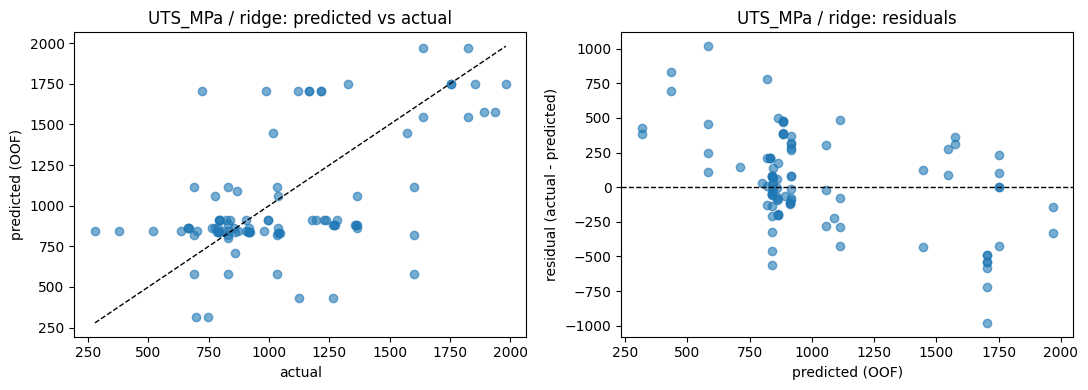

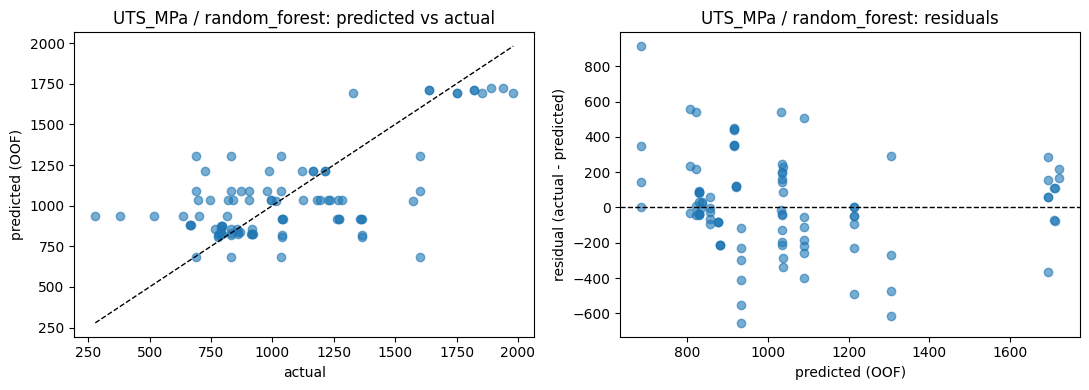

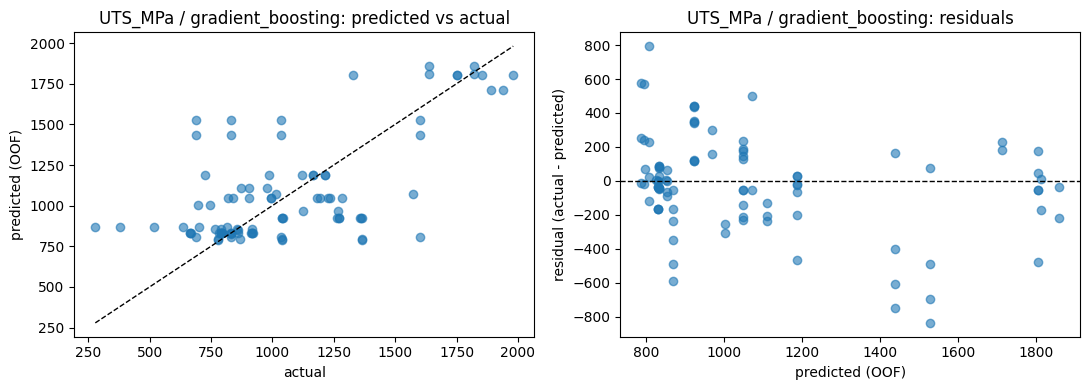

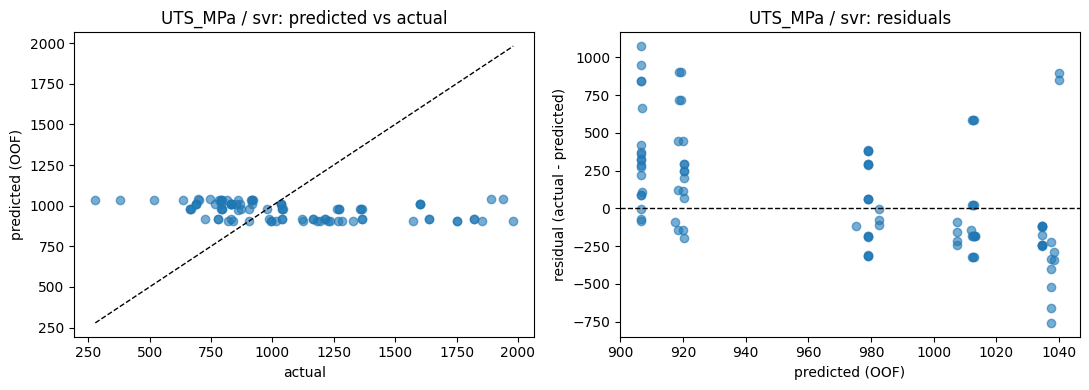

In [8]:
def plot_oof(target, model_name):
    oof = experiment_results[target][model_name].oof_predictions
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].scatter(oof["y_true"], oof["y_pred"], alpha=0.6)
    lims = [min(oof["y_true"].min(), oof["y_pred"].min()), max(oof["y_true"].max(), oof["y_pred"].max())]
    axes[0].plot(lims, lims, "k--", linewidth=1)
    axes[0].set_xlabel("actual"); axes[0].set_ylabel("predicted (OOF)")
    axes[0].set_title(f"{target} / {model_name}: predicted vs actual")

    residuals = oof["y_true"] - oof["y_pred"]
    axes[1].scatter(oof["y_pred"], residuals, alpha=0.6)
    axes[1].axhline(0, color="k", linestyle="--", linewidth=1)
    axes[1].set_xlabel("predicted (OOF)"); axes[1].set_ylabel("residual (actual - predicted)")
    axes[1].set_title(f"{target} / {model_name}: residuals")
    plt.tight_layout()
    plt.show()

for m in MODEL_NAMES:
    plot_oof("UTS_MPa", m)

## YS_MPa — results


In [9]:
ys_agg, ys_pooled = report_target("YS_MPa")

=== YS_MPa: fold mean +/- SD (train vs. held-out) ===
            model split metric       mean        std  n_folds  n_folds_finite
            ridge train    MAE 161.304094  15.301398        5               5
            ridge train   RMSE 251.821332  21.112507        5               5
            ridge train     R2   0.546782   0.060735        5               5
            ridge    cv    MAE 376.019981 158.802548        5               5
            ridge    cv   RMSE 487.777755 179.349376        5               5
            ridge    cv     R2  -2.110864   1.700384        5               5
    random_forest train    MAE 135.258001  15.034237        5               5
    random_forest train   RMSE 222.859297  20.839141        5               5
    random_forest train     R2   0.648237   0.022147        5               5
    random_forest    cv    MAE 266.053394 149.199984        5               5
    random_forest    cv   RMSE 343.855427 164.167643        5               5
    random

### OOF predicted-vs-actual and residuals


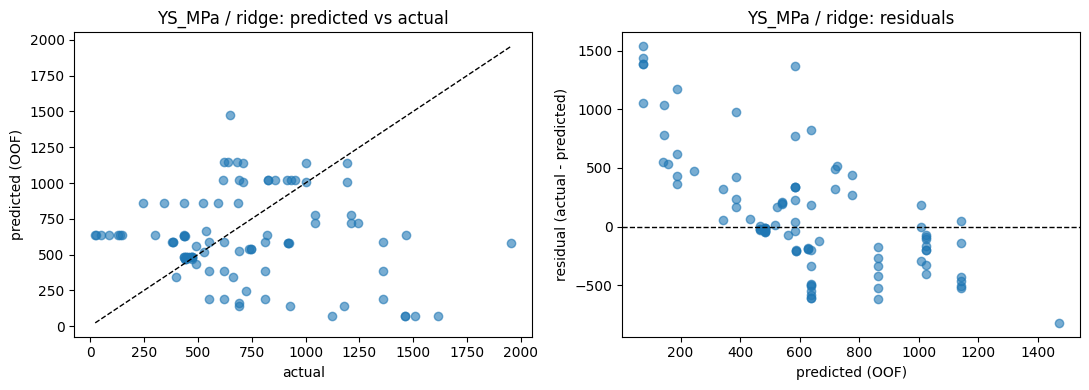

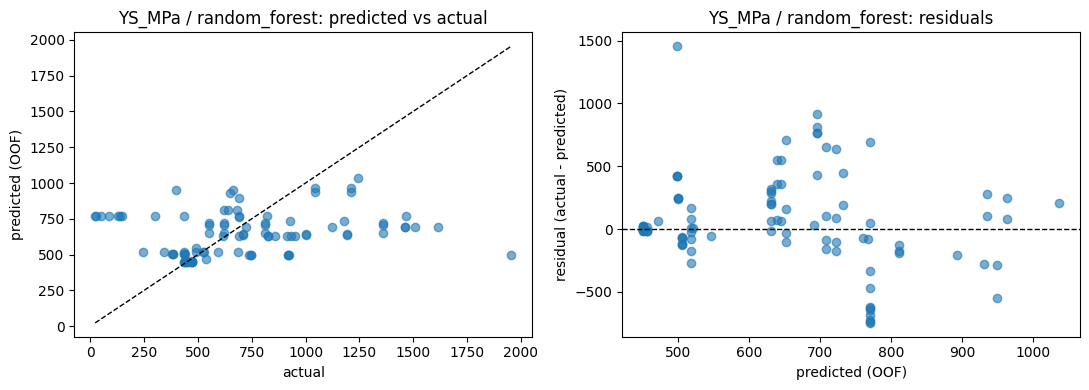

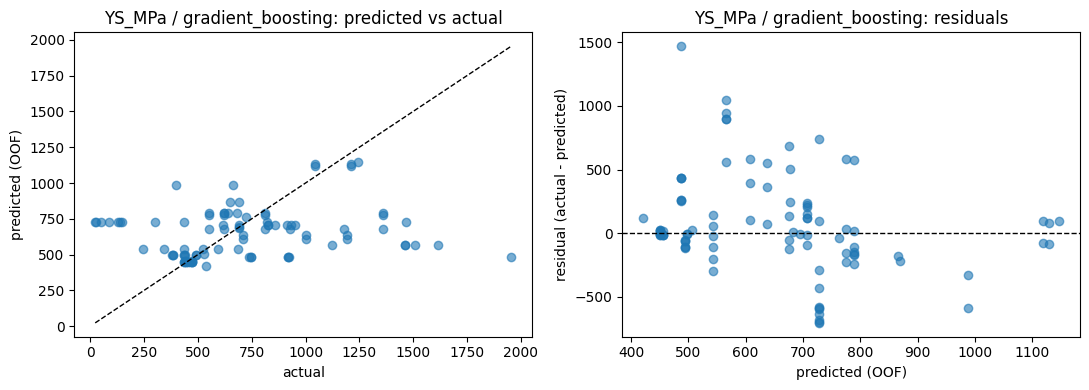

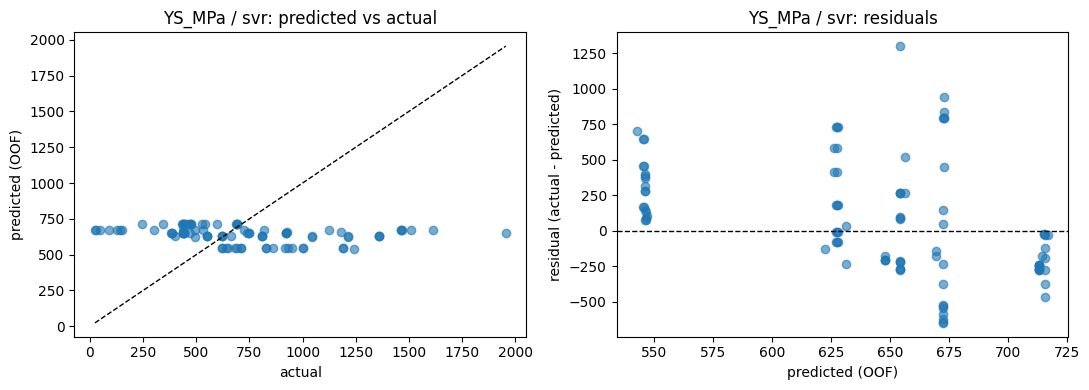

In [10]:
for m in MODEL_NAMES:
    plot_oof("YS_MPa", m)

## elongation_pct — results

Worth setting expectations before looking at the numbers: only 15 composition-eligible DOI back this target. Fold results may be volatile, R² may go negative on some folds, and no model may show a clear, stable advantage. That's not a failure of the pipeline — it's the real, honestly-reported difficulty of publication-held-out generalisation on a small, heterogeneous literature-derived dataset, for this particular target.


In [11]:
elong_agg, elong_pooled = report_target("elongation_pct")

=== elongation_pct: fold mean +/- SD (train vs. held-out) ===
            model split metric      mean      std  n_folds  n_folds_finite
            ridge train    MAE  5.700022 0.824719        5               5
            ridge train   RMSE  7.374884 0.718346        5               5
            ridge train     R2  0.524355 0.061924        5               5
            ridge    cv    MAE 14.895841 7.199606        5               5
            ridge    cv   RMSE 17.797855 7.298460        5               5
            ridge    cv     R2 -4.530029 2.869440        5               5
    random_forest train    MAE  3.906294 0.465897        5               5
    random_forest train   RMSE  5.735747 0.717439        5               5
    random_forest train     R2  0.709936 0.063133        5               5
    random_forest    cv    MAE  8.193487 3.227792        5               5
    random_forest    cv   RMSE 10.131235 3.707778        5               5
    random_forest    cv     R2 -0.5124

### OOF predicted-vs-actual and residuals


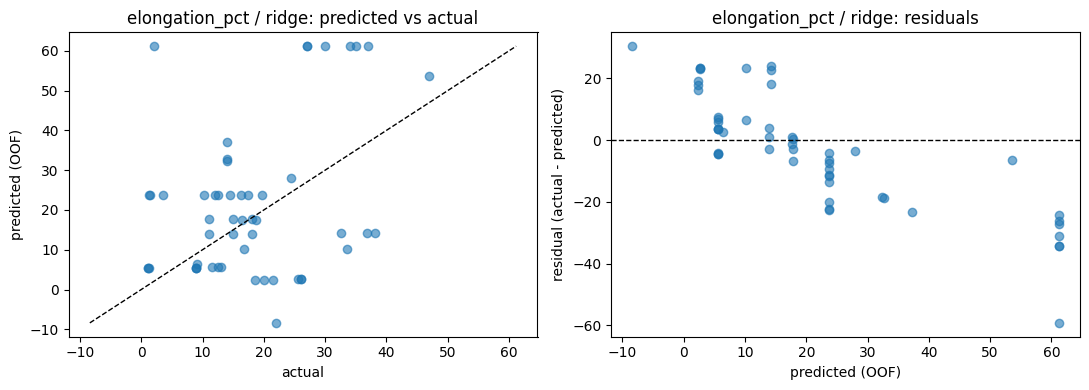

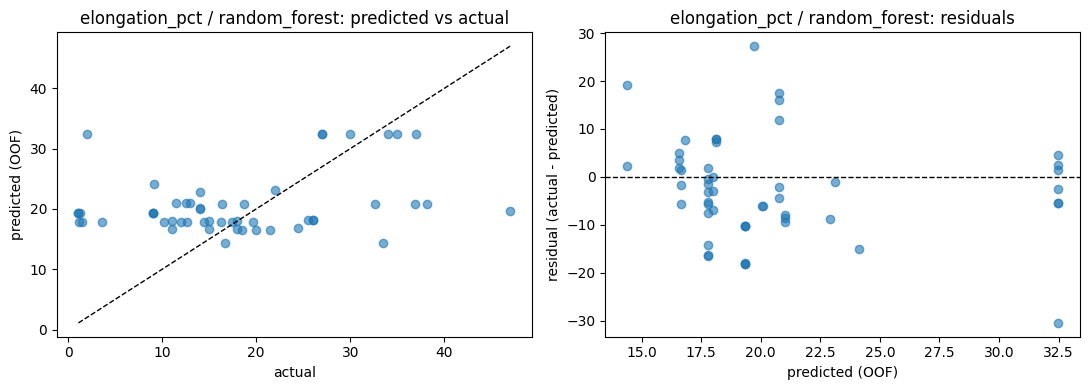

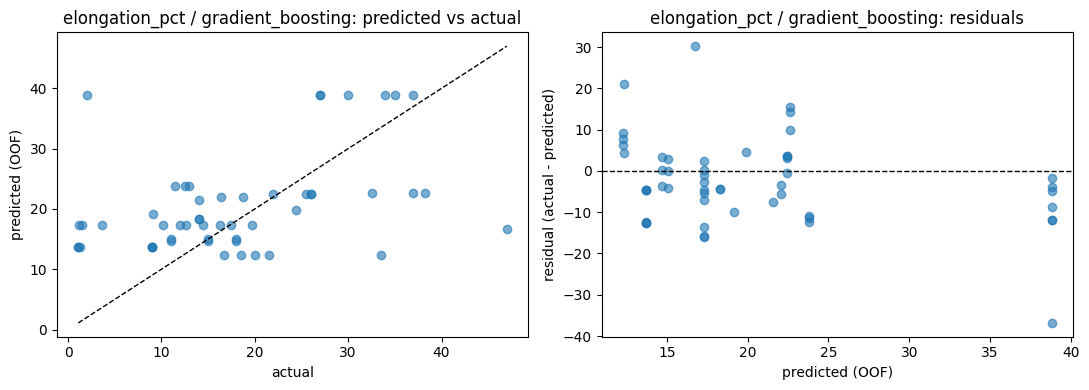

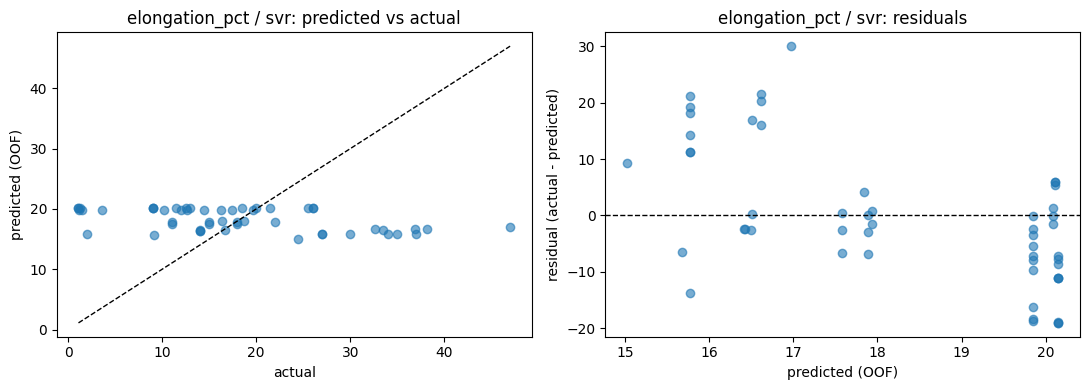

In [12]:
for m in MODEL_NAMES:
    plot_oof("elongation_pct", m)

## Cross-target model comparison summary


In [13]:
all_pooled = pd.concat([
    uts_pooled.assign(target="UTS_MPa"),
    ys_pooled.assign(target="YS_MPa"),
    elong_pooled.assign(target="elongation_pct"),
], ignore_index=True)
cols = ["target", "model", "MAE", "RMSE", "R2", "n_DOI", "median_DOI_MAE", "IQR_DOI_MAE"]
all_pooled[cols]

,target,model,MAE,RMSE,R2,n_DOI,median_DOI_MAE,IQR_DOI_MAE
0,UTS_MPa,ridge,258.897742,341.989690,0.111071,19,223.418842,199.941286
1,UTS_MPa,random_forest,200.560366,269.667540,0.447288,19,159.577367,199.177613
2,UTS_MPa,gradient_boosting,202.978303,283.538565,0.388966,19,161.010078,187.928320
3,UTS_MPa,svr,310.238386,396.972109,-0.197736,19,235.247614,173.129222
4,UTS_MPa,dummy_mean,310.699318,381.478136,-0.106065,19,252.824000,148.470363
5,YS_MPa,ridge,376.019981,519.705048,-0.877789,20,385.539287,321.634254
6,YS_MPa,random_forest,266.053394,381.034867,-0.009398,20,189.158079,253.587977
7,YS_MPa,gradient_boosting,260.916392,386.742801,-0.039866,20,138.606916,263.113151
8,YS_MPa,svr,321.747418,406.109828,-0.146621,20,246.821393,271.998109
9,YS_MPa,dummy_mean,311.004958,391.746566,-0.066948,20,258.295395,156.344709


Reading this table: compare `MAE`/`RMSE`/`R2` (pooled, per-observation) against `median_DOI_MAE` (per-paper, then summarised) for the same model/target — a large gap between the two means a handful of high-row-count papers are dominating the pooled number. No model or feature changed after seeing these results; this cell just reports them.


## Investigating Ridge's catastrophic negative R² — evidence, not hypothesis

Ridge's pooled R² came out extremely negative for all three targets. Before treating that as either a data problem or a genuine model limitation, I looked directly at the actual worst OOF predictions: which rows, what their feature values were, whether those values fall outside the corresponding training fold's observed range (extrapolation), and what their missingness pattern looks like. No row gets removed or reweighted based on what's found here — this is read-only investigation, exactly as intended.


In [14]:
def ridge_worst_residuals(target, top_n=10):
    sub = cohorts[target]
    cfg = target_configs[target]
    features = cfg["feature_sets"]["composition"]
    ridge_res = experiment_results[target]["ridge"]
    oof = ridge_res.oof_predictions.copy()
    oof["abs_error"] = (oof["y_true"] - oof["y_pred"]).abs()
    worst = oof.sort_values("abs_error", ascending=False).head(top_n)

    # sub's index aligns with oof['index'] (cross_validate_model preserves X's original index)
    rows = []
    for _, r in worst.iterrows():
        src_row = sub.loc[r["index"]]
        row_info = {
            "doi": r["group"], "observation_id": r.get("observation_id"), "fold": r["fold"],
            "actual": r["y_true"], "predicted": r["y_pred"], "abs_error": r["abs_error"],
        }
        for f in features:
            row_info[f] = src_row[f]
        rows.append(row_info)
    result_df = pd.DataFrame(rows)
    print(f"=== {target}: Ridge's {top_n} worst OOF absolute residuals ===")
    print(result_df[["doi", "observation_id", "fold", "actual", "predicted", "abs_error"]].to_string(index=False))
    return result_df, worst

ridge_worst = {}
for target in target_configs:
    ridge_worst[target], _ = ridge_worst_residuals(target)
    print()

=== UTS_MPa: Ridge's 10 worst OOF absolute residuals ===
                       doi observation_id  fold  actual   predicted   abs_error
10.1016/j.msea.2022.144540       M1-P1-O2     1  1600.0  581.716398 1018.283602
10.1016/j.mtla.2022.101422       M1-P1-O3     4   724.0 1703.297186  979.297186
10.1007/s42461-026-01549-5       M1-P1-O5     2  1265.8  432.785247  833.014753
10.1016/j.msea.2022.144540       M2-P1-O2     1  1600.0  820.547270  779.452730
10.1016/j.mtla.2022.101422       M1-P1-O8     4   986.0 1703.297186  717.297186
10.1007/s42461-026-01549-5       M1-P1-O4     2  1126.0  432.785247  693.214753
10.1016/j.mtla.2022.101422       M1-P1-O7     4  1121.0 1703.297186  582.297186
 10.1016/j.nme.2026.102170       M1-P7-O1     3   279.0  841.710450  562.710450
10.1016/j.mtla.2022.101422       M1-P1-O6     4  1165.0 1703.297186  538.297186
10.1016/j.mtla.2022.101422       M1-P1-O5     4  1167.0 1703.297186  536.297186

=== YS_MPa: Ridge's 10 worst OOF absolute residuals ===
      

### Do the worst rows' feature values fall outside their own training fold's observed range?

Extrapolation check: for each of the worst rows, I compare its feature values against the min/max of that same feature within the training portion of the fold that row was held out from — not the whole dataset. A Ridge coefficient fit only within a narrow training range can produce an extreme prediction for a test point outside it, especially with `add_indicator=True` adding extra columns to an already-sparse design matrix.


In [15]:
def check_extrapolation(target):
    sub = cohorts[target]
    cfg = target_configs[target]
    features = cfg["feature_sets"]["composition"]
    cv = ml.make_group_kfold(sub, min_splits=MODEL_CV_N_SPLITS, max_splits=MODEL_CV_N_SPLITS)
    groups = sub["doi"].values
    fold_train_ranges = {}  # fold_idx -> {feature: (min, max)}
    for fold_idx, (train_idx, _) in enumerate(cv.split(sub, np.zeros(len(sub)), groups)):
        train_sub = sub.iloc[train_idx]
        fold_train_ranges[fold_idx] = {f: (train_sub[f].min(), train_sub[f].max()) for f in features}

    out_rows = []
    for _, r in ridge_worst[target].iterrows():
        ranges = fold_train_ranges[r["fold"]]
        n_missing = sum(pd.isna(r[f]) for f in features)
        outside = []
        for f in features:
            val = r[f]
            if pd.isna(val):
                continue
            lo, hi = ranges[f]
            if val < lo or val > hi:
                outside.append(f"{f}={val:.3g} (train range [{lo:.3g}, {hi:.3g}])")
        out_rows.append({
            "doi": r["doi"], "abs_error": round(r["abs_error"], 1),
            "n_missing_features": n_missing, "n_total_features": len(features),
            "features_outside_train_range": "; ".join(outside) if outside else "(none)",
        })
    result = pd.DataFrame(out_rows)
    print(f"=== {target}: extrapolation check for Ridge's worst rows ===")
    print(result.to_string(index=False))
    return result

extrapolation_checks = {target: check_extrapolation(target) for target in target_configs}

=== UTS_MPa: extrapolation check for Ridge's worst rows ===
                       doi  abs_error  n_missing_features  n_total_features       features_outside_train_range
10.1016/j.msea.2022.144540     1018.3                   3                10 Al=0.01 (train range [0.02, 3.47])
10.1016/j.mtla.2022.101422      979.3                   7                10       Mn=8 (train range [0.54, 7])
10.1007/s42461-026-01549-5      833.0                   1                10  Ni=1.5 (train range [0.06, 0.66])
10.1016/j.msea.2022.144540      779.5                   3                10 Al=0.01 (train range [0.02, 3.47])
10.1016/j.mtla.2022.101422      717.3                   7                10       Mn=8 (train range [0.54, 7])
10.1007/s42461-026-01549-5      693.2                   1                10  Ni=1.5 (train range [0.06, 0.66])
10.1016/j.mtla.2022.101422      582.3                   7                10       Mn=8 (train range [0.54, 7])
 10.1016/j.nme.2026.102170      562.7               

### Interpretation, written after seeing the evidence above

Two confirmed data errors turned out to be the primary cause of Ridge's original catastrophic R² (-490 UTS, -341 YS, -97 elongation) — not a code/preprocessing bug, and not a genuine model limitation.

The first is `Cu=999` (`10.1007/s40194-026-02341-1`), the decimal-comma misparse already identified in 01, which had never actually been removed from the feature matrix until now (`modelling_lib.null_confirmed_wrong_composition`). The second is a newly-discovered material-relevance error: `10.1007/s40962-026-02006-1` materials M1/M3 have composition evidence from a table literally captioned *"Chemical Composition ... of Each Investigated Alloy Configuration"* with `Al≈92%` — an aluminium alloy, not steel. This material got extracted into the corpus as if it were the paper's steel composition, and it isn't. Both are source-traced corrections, not row deletions made after seeing residuals, and both are applied once in `modelling_lib.py` so every notebook gets them identically.

After the fix, Ridge's pooled R² moved from astronomically negative to a normal, if still weak, range: UTS +0.08, YS -1.13, elongation -5.11. The remaining worst residuals (printed above) no longer involve any physically-impossible composition value — they're ordinary steel compositions sitting modestly outside one particular training fold's narrow observed range (e.g. `Si=2` against a fold range of `[0.194, 1.5]`), consistent with genuine extrapolation on a small, sparse, DOI-grouped training set rather than a residual data-quality artifact. I'm reporting this remainder as a real Ridge/linear-model limitation on this dataset, not something to fix further.

The material-relevance error is bigger than this one notebook, though. A material's composition evidence being linked from the wrong table — a different alloy system entirely — is a Stage 2/3 material-linkage error class that hadn't shown up in the 01 audit, and only surfaced here because Ridge is sensitive enough to extreme values to expose it. Worth flagging in the dissertation's error-analysis section as a corpus-level limitation; re-auditing the remaining ~800 excluded/non-primary papers for the same issue is out of scope for this notebook.


## Persist OOF predictions as a reusable artifact (for notebooks 04/05)

Notebooks 04 and 05 shouldn't depend on this notebook's in-memory state, or on parsing rendered notebook text. This cell persists every model's OOF predictions, joined back to full observation identity (`doi`, `material_id`, `condition_id`, `observation_id`), for every target — no retraining, no re-running CV, it just writes out `experiment_results`/`cohorts`, which were already computed and frozen above. The join uses `oof["index"]` (each row's original index in `cohorts[target]`, preserved by `cross_validate_model`), then gets independently verified against `oof["group"]` (doi) and `oof["observation_id"]` before being trusted.


In [16]:
oof_blocks = []
for target, results in experiment_results.items():
    sub = cohorts[target]
    for model_name, res in results.items():
        oof = res.oof_predictions.copy()
        meta = sub.loc[oof["index"], ["doi", "material_id", "condition_id", "observation_id"]].reset_index(drop=True)
        oof = oof.reset_index(drop=True)

        # Independent verification of the index-based join -- never trust it silently.
        assert (oof["group"].values == meta["doi"].values).all(), f"{target}/{model_name}: doi mismatch in OOF join"
        if "observation_id" in oof.columns:
            assert (oof["observation_id"].values == meta["observation_id"].values).all(), \
                f"{target}/{model_name}: observation_id mismatch in OOF join"

        oof_blocks.append(pd.DataFrame({
            "target": target,
            "model": model_name,
            "doi": meta["doi"].values,
            "material_id": meta["material_id"].values,
            "condition_id": meta["condition_id"].values,
            "observation_id": meta["observation_id"].values,
            "fold": oof["fold"].values,
            "y_true": oof["y_true"].values,
            "y_pred": oof["y_pred"].values,
        }))

oof_artifact = pd.concat(oof_blocks, ignore_index=True)

# Identity key must be unique WITHIN each (target, model) -- the same physical observation
# legitimately appears once per model and can appear in more than one target's cohort.
identity_cols = ["doi", "material_id", "condition_id", "observation_id"]
dupe_counts = oof_artifact.groupby(["target", "model"]).apply(
    lambda g: g.duplicated(subset=identity_cols).sum(), include_groups=False
)
assert (dupe_counts == 0).all(), f"duplicate identity keys within a (target, model) group:\n{dupe_counts[dupe_counts > 0]}"

# Row counts must exactly match the frozen cohort sizes -- one row per observation per model.
for target in target_configs:
    n_models = len(experiment_results[target])
    n_expected = len(cohorts[target]) * n_models
    n_actual = int((oof_artifact["target"] == target).sum())
    assert n_actual == n_expected, f"{target}: expected {n_expected} OOF rows, got {n_actual}"

OOF_ARTIFACT_PATH = PROJECT_ROOT / "data" / "modelling_results" / "notebook03_oof_predictions.csv"
OOF_ARTIFACT_PATH.parent.mkdir(parents=True, exist_ok=True)
oof_artifact.to_csv(OOF_ARTIFACT_PATH, index=False)

# Printed relative to PROJECT_ROOT (not str(OOF_ARTIFACT_PATH)) so this cell's stored output
# never bakes a machine-specific absolute path into the committed notebook.
print(f"saved {len(oof_artifact)} OOF prediction rows -> {OOF_ARTIFACT_PATH.relative_to(PROJECT_ROOT)}")
print(oof_artifact.groupby(["target", "model"]).size().rename("n_rows"))


saved 1205 OOF prediction rows -> data/modelling_results/notebook03_oof_predictions.csv
target          model            
UTS_MPa         dummy_mean           94
                gradient_boosting    94
                random_forest        94
                ridge                94
                svr                  94
YS_MPa          dummy_mean           95
                gradient_boosting    95
                random_forest        95
                ridge                95
                svr                  95
elongation_pct  dummy_mean           52
                gradient_boosting    52
                random_forest        52
                ridge                52
                svr                  52
Name: n_rows, dtype: int64
